# 03. Multiloop, feedforward and cascade structures

Original study laboratory. All generated data are synthetic.

A measured inlet disturbance can be canceled nominally by $u=v-d$.
A cascade loop measures the fast actuator variable and closes an inner loop
before the slower concentration controller. Multivariable interactions are
summarized by $\Lambda=K\circ(K^{-1})^T$; a static decoupler $K^{-1}$
cancels steady interaction, not all transient dynamics. Compare only cases
with the same disturbance location and measurement information.

## Prepare the environment

Run the next cell once in Colab. Locally, install `requirements.txt` and open this notebook within the repository. The cell only downloads the public repository when running in Colab and no checkout is present.

In [1]:
from pathlib import Path
import sys, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not Path("python/intelligent_control").exists():
    checkout = Path("/content/intelligent-process-control")
    if not checkout.exists():
        subprocess.run(["git", "clone", "https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(checkout / "requirements.txt")], check=True)
    import os
    os.chdir(checkout)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python/intelligent_control").is_dir())
sys.path.insert(0, str(ROOT / "python"))
print("Environment ready")

Environment ready


## Read the method visually

![Unit 03 conceptual diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/course/figures/learning/unit-03.png)

The short inner path uses the measured actuator/flow variable; the long outer path uses concentration. Cascade can correct an actuator disturbance before it strongly affects concentration. Compare it only with the single-loop case having that same actuator. The feedforward pair is a separate comparison, and its disturbance measurement is additional information.

The conceptual diagram is deliberately separate from the computed experiment below. [Editable SVG](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/figures/learning/unit-03.svg).

## Run the experiment

Read the model and controller definitions alongside the results. Every rerun writes the metrics, trace CSV files and figure from the current parameters. Unit 7 includes nested optimization and costs more than the other units.

In [2]:
from intelligent_control.experiments import run_unit
import json
result = run_unit(3, ROOT / "laboratories/03-control-structures/results")
print(json.dumps(result["summary"], indent=2))

{
  "single loop with actuator": {
    "iae": 3.4786881911280805,
    "ise": 0.4466059107646795,
    "itae": 134.23572425238683,
    "control_energy": 31.780902079031783,
    "total_variation": 1.7595629312866872,
    "constraint_violation": 0.0,
    "final_error": -0.016108778046034278
  },
  "cascade": {
    "iae": 2.642941088624113,
    "ise": 0.4241762562323778,
    "itae": 84.04468106647386,
    "control_energy": 32.31726322963261,
    "total_variation": 2.8813738798080686,
    "constraint_violation": 0.0,
    "final_error": 0.0003687518239480214
  },
  "decentralized": {
    "final_output": [
      0.5997749003465047,
      0.6503265314051084
    ],
    "max_actuator": 0.6040000000000001
  },
  "decoupled": {
    "final_output": [
      0.5999878859809327,
      0.6497882447638212
    ],
    "max_actuator": 0.5049814814814815
  },
  "feedback": {
    "iae": 2.8622955662746614,
    "ise": 0.3630729165011101,
    "itae": 103.07106908774517,
    "control_energy": 24.714924617917937,

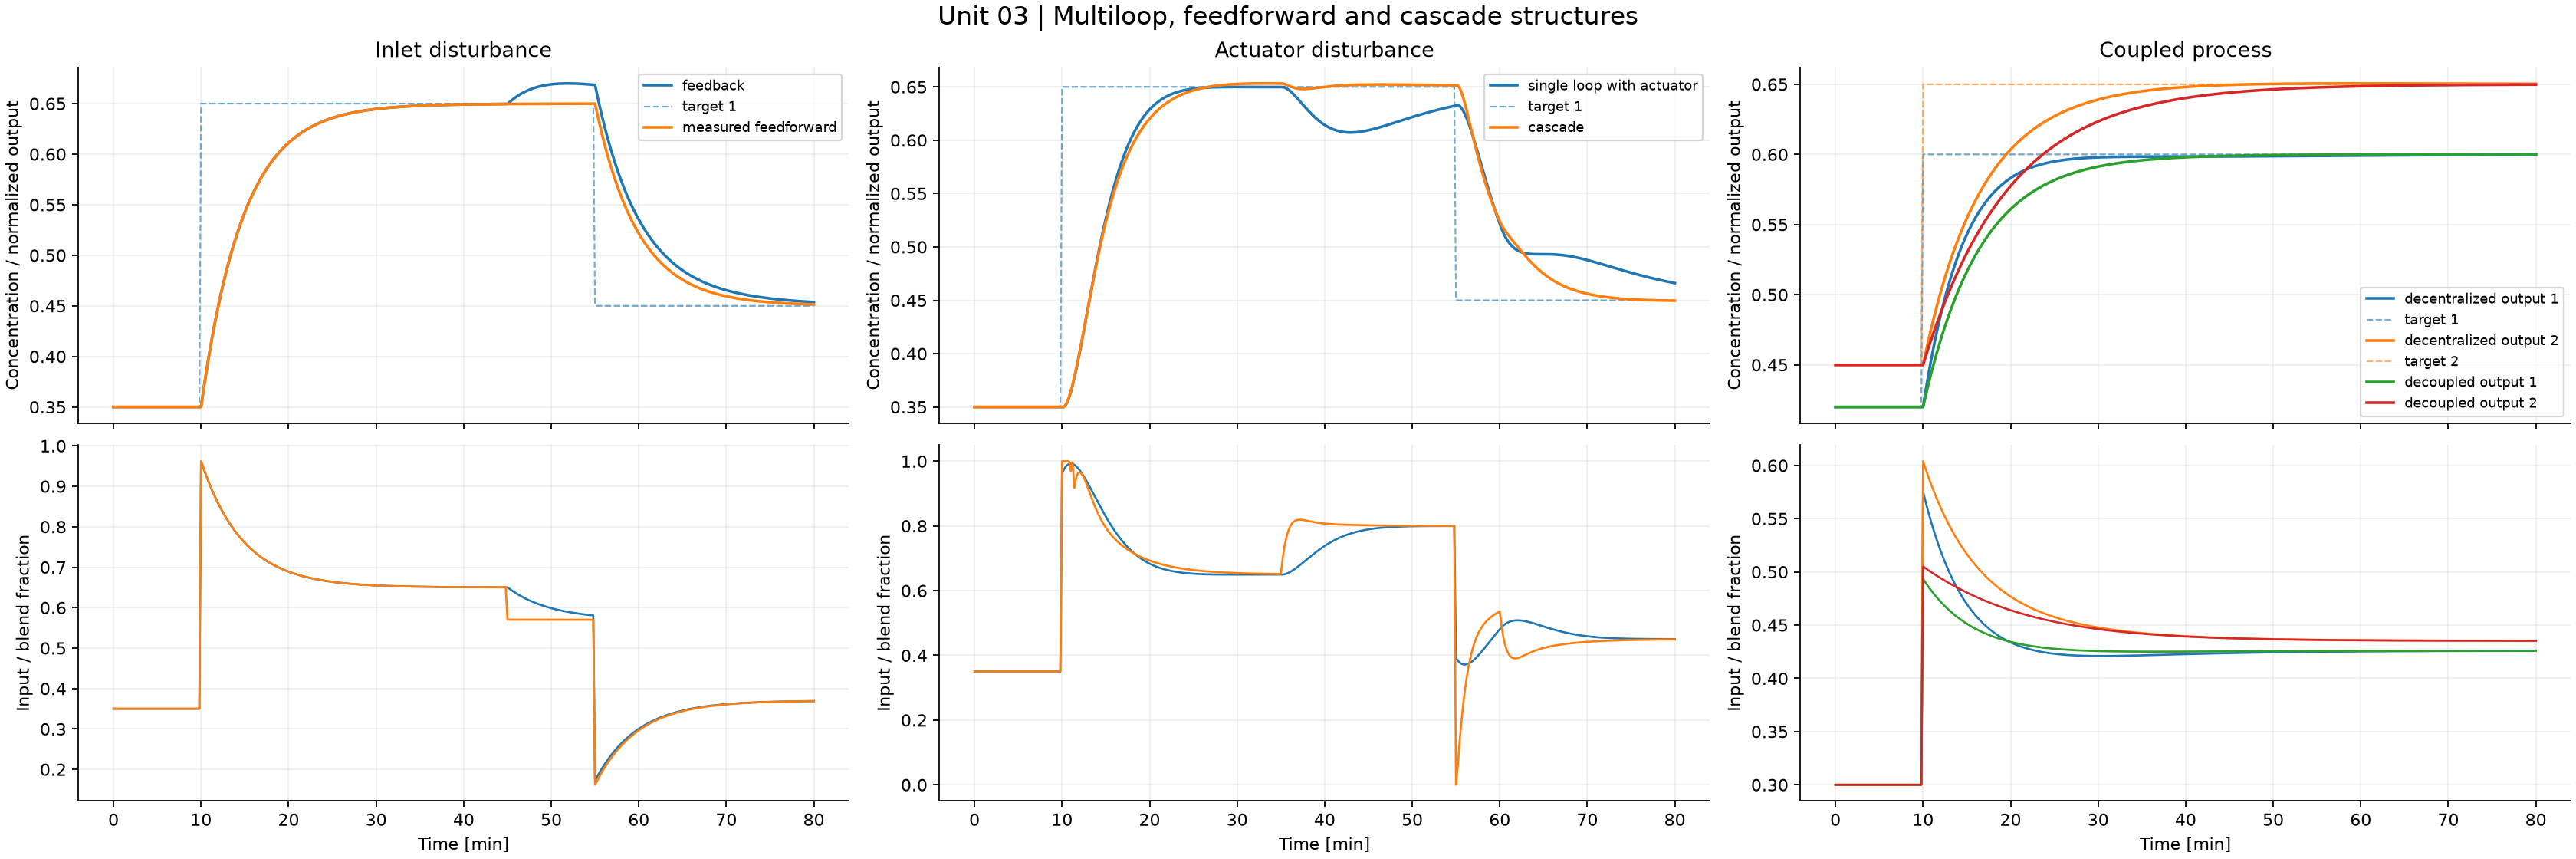

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "laboratories/03-control-structures/results/comparison.png")))

## Inspect the evidence

1. Identify the physical assumptions, input limits and units.
2. Explain a visible transient using the governing equation.
3. Change one model or controller parameter, rerun and compare the saved metrics.
4. State what the test does and does not establish.

Use the [course guide](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/README.md), [worked problems](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/problem-sets/README.md) and [benchmark inventory](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/README.md) for the corresponding derivations and extensions.

## Apply this unit to the article benchmarks

[Original article names and detailed TikZ atlas](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/DIAGRAMS.md) · [Download the vector atlas](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/figures/tikz/benchmark-atlas.pdf)

![Tennessee Eastman process control problem — article section 3.13](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/figures/tikz/13-tennessee-eastman.png)

The atlas identifies every benchmark by its original paper name and repository alias, with equipment, states and signals. The Tennessee Eastman companion plate maps the 12 commands and 41 measurements.

[Worked benchmark study for Unit 03](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/learning/unit-03.md)

![Unit 03 benchmark study](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/learning/figures/unit-03.png)

Read the per-model method, chosen signals, numerical results and interpretation in the linked study. The learning track declares its local-model approximations and separates equation-based experiments from external datasets and simulators. It does not turn an unavailable measured record into a synthetic benchmark result.